# 온라인 교육 콘텐츠 구독 서비스: 시계열 코호트 분석

온라인 교육 구독 서비스의 이벤트 로그로 유저가 언제 이탈하고, 어떤 학습 경험이 구독 유지로 이어지는지 분석한 노트북입니다. 팀 프로젝트에서 제가 맡은 시계열 코호트 분석 부분을 정리했습니다.

- 원본 데이터는 비공개라 포함하지 않았습니다. 실행하려면 `data/` 폴더에 CSV 파일이 필요합니다.
- 용어: **첫 구독**(complete_subscription), **갱신**(renew_subscription), **재구독**(resubscribe, 해지 후 다시 구독)

## 0. 데이터 불러오기

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

DATA_DIR = '2data/'
START, END = '2023-05-01', '2024-01-01'   # 분석 기간: 2023.05 ~ 2023.12

def load(file_name):
    df = pd.read_csv(DATA_DIR + file_name)
    df.columns = [c.replace('plan.price', 'plan_price') for c in df.columns]
    df['client_event_time'] = pd.to_datetime(df['client_event_time'], errors='coerce')
    df = df[(df['client_event_time'] >= START) & (df['client_event_time'] < END)].copy()
    df['month'] = df['client_event_time'].dt.to_period('M')
    return df

signup = load('signup.csv')                    # 가입
sub    = load('complete_subscription.csv')     # 첫 구독
renew  = load('renew_subscription.csv')        # 갱신
resub  = load('resubscribe.csv')               # 재구독
start  = load('start_content.csv')             # 콘텐츠 시작
end    = load('end_content.csv')               # 콘텐츠 완주
lesson = load('lesson.csv')                    # 레슨 완료

for name, df in [('signup', signup), ('sub', sub), ('renew', renew), ('resub', resub),
                 ('start', start), ('end', end), ('lesson', lesson)]:
    print(f'{name:7s} {len(df):>9,}행  유저 {df["user_id"].nunique():>7,}명')

signup     55,954행  유저  55,954명
sub         4,941행  유저   4,868명
renew       8,399행  유저   3,976명
resub         574행  유저     563명
start      74,910행  유저  32,987명
end        46,343행  유저  13,481명
lesson  1,048,321행  유저  23,187명


### 공통 함수

- `month_diff`: 두 월(Period) 사이의 개월 수
- `keep_continuous`: 0개월 차부터 끊기지 않고 이어진 달만 남깁니다. 중간에 한 달이라도 빠지면 그 뒤는 유지로 세지 않습니다.
- `first_event`: 유저별 첫 이벤트만 남깁니다.

In [6]:
def month_diff(later, earlier):
    return (later.dt.year - earlier.dt.year) * 12 + (later.dt.month - earlier.dt.month)

def keep_continuous(df, user_col='user_id', idx_col='month_index'):
    df = df.drop_duplicates([user_col, idx_col]).sort_values([user_col, idx_col])
    return df[df[idx_col] == df.groupby(user_col).cumcount()]

def first_event(df):
    return df.sort_values('client_event_time').drop_duplicates('user_id', keep='first').copy()

def plot_heatmap(pivot, title, cmap='PuBu', label='유지율 (%)'):
    plt.figure(figsize=(12, 7))
    sns.heatmap(pivot, annot=True, fmt='.1f', cmap=cmap, vmin=0, vmax=100,
                mask=pivot.isnull(), cbar_kws={'label': label})
    plt.title(title, fontsize=15, pad=15)
    plt.xlabel('경과 개월')
    plt.ylabel('코호트 (월)')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 1. 월별 유입 현황

### 1-1. 월별 가입 · 재구독 · 갱신 유저 구성

한 유저가 같은 달에 여러 이벤트를 가지면 가입 > 재구독 > 갱신 순으로 1번만 셉니다.

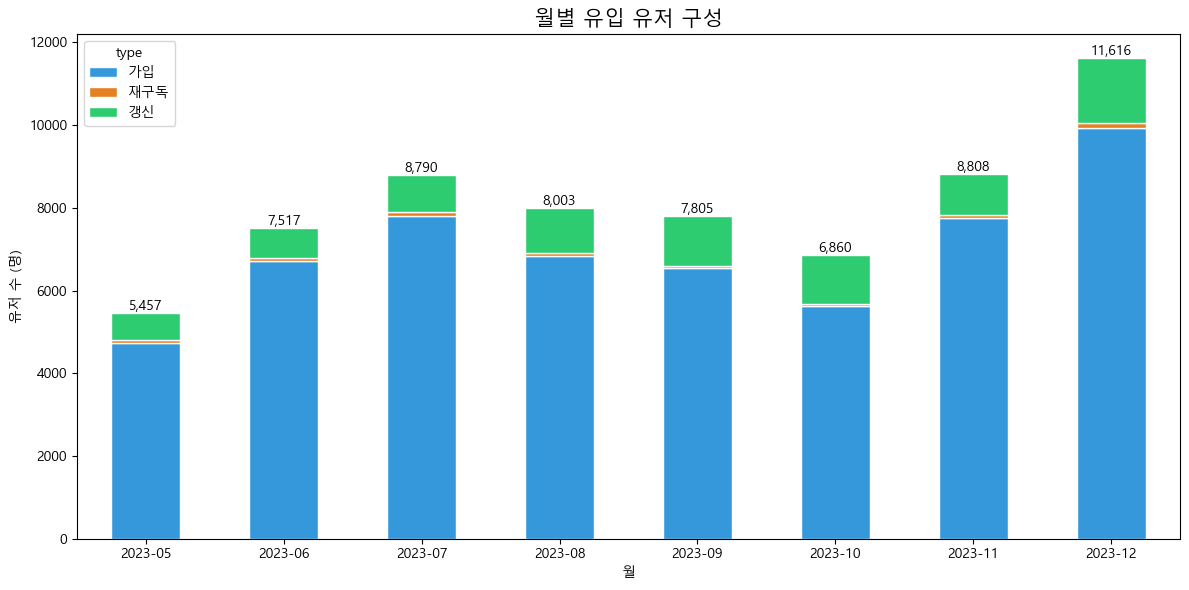

type,가입,재구독,갱신
month,,,
2023-05,4739,59,659
2023-06,6706,78,733
2023-07,7812,79,899
2023-08,6834,76,1093
2023-09,6539,67,1199
2023-10,5630,50,1180
2023-11,7754,63,991
2023-12,9940,102,1574


In [7]:
combined = pd.concat([
    signup[['user_id', 'month']].assign(type='가입'),
    resub[['user_id', 'month']].assign(type='재구독'),
    renew[['user_id', 'month']].assign(type='갱신'),
])
priority = {'가입': 1, '재구독': 2, '갱신': 3}
combined['priority'] = combined['type'].map(priority)
monthly_users = (combined.sort_values(['month', 'user_id', 'priority'])
                 .drop_duplicates(['month', 'user_id'])
                 .groupby(['month', 'type']).size().unstack(fill_value=0))
monthly_users = monthly_users[['가입', '재구독', '갱신']]
monthly_users.index = monthly_users.index.astype(str)

ax = monthly_users.plot(kind='bar', stacked=True, figsize=(12, 6),
                        color=['#3498db', '#e67e22', '#2ecc71'], edgecolor='white')
for i, total in enumerate(monthly_users.sum(axis=1)):
    ax.text(i, total, f'{total:,}', ha='center', va='bottom')
plt.title('월별 유입 유저 구성', fontsize=15)
plt.xlabel('월')
plt.ylabel('유저 수 (명)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

monthly_users

### 1-2. 월별 첫 구독 유저 수

In [8]:
first_sub = first_event(sub)
monthly_first_sub = first_sub.groupby('month')['user_id'].nunique()
monthly_signup = signup.groupby('month')['user_id'].nunique()

summary = pd.DataFrame({'가입 유저': monthly_signup, '첫 구독 유저': monthly_first_sub})
summary['가입 대비 첫 구독 (%)'] = (summary['첫 구독 유저'] / summary['가입 유저'] * 100).round(1)
summary.index = summary.index.astype(str)
summary

,가입 유저,첫 구독 유저,가입 대비 첫 구독 (%)
month,,,
2023-05,4739,386,8.1
2023-06,6706,657,9.8
2023-07,7812,801,10.3
2023-08,6834,520,7.6
2023-09,6539,584,8.9
2023-10,5630,366,6.5
2023-11,7754,567,7.3
2023-12,9940,987,9.9


> 가입 대비 첫 구독 비율은 같은 달 기준의 단순 비교입니다. 가입한 달과 첫 구독한 달이 다른 유저도 있어 정확한 전환율은 아닙니다.

## 2. 코호트별 월별 유지율

첫 구독 · 갱신 · 재구독 세 코호트를 각각 만들고, 이후 달에 갱신 결제가 있으면 유지로 봤습니다.

- 관측 기간(2023.12)을 넘는 칸은 빈칸으로 둡니다.

### 2-1. 첫 구독 코호트

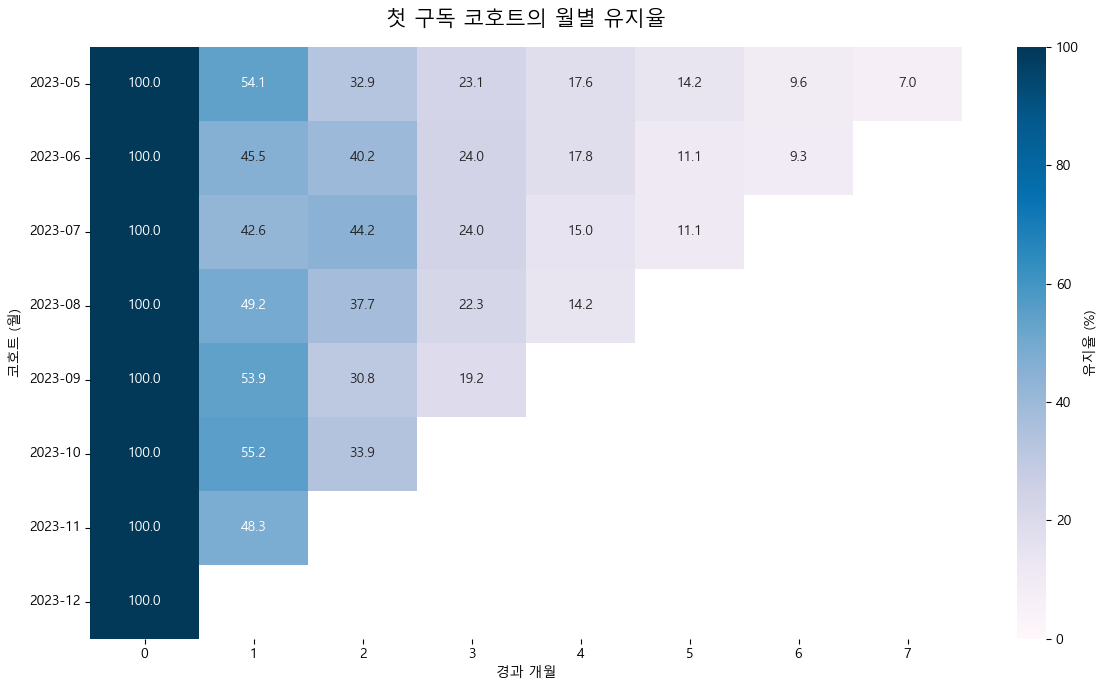

month_index,0,1,2,3,4,5,6,7
cohort_month,,,,,,,,
2023-05,100.0,54.1,32.9,23.1,17.6,14.2,9.6,7.0
2023-06,100.0,45.5,40.2,24.0,17.8,11.1,9.3,NaN
2023-07,100.0,42.6,44.2,24.0,15.0,11.1,NaN,NaN
2023-08,100.0,49.2,37.7,22.3,14.2,NaN,NaN,NaN
2023-09,100.0,53.9,30.8,19.2,NaN,NaN,NaN,NaN
2023-10,100.0,55.2,33.9,NaN,NaN,NaN,NaN,NaN
2023-11,100.0,48.3,NaN,NaN,NaN,NaN,NaN,NaN
2023-12,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
max_month = renew['month'].max()

def renew_retention(cohort_df, continuous=False):
    # cohort_df: user_id, cohort_month
    sizes = cohort_df.groupby('cohort_month')['user_id'].nunique()
    m = pd.merge(cohort_df, renew[['user_id', 'month']], on='user_id')
    m['month_index'] = month_diff(m['month'], m['cohort_month'])
    m = m[m['month_index'] >= 0]
    if continuous:
        m = keep_continuous(m)
    else:
        m = m[m['month_index'] > 0]
    pivot = m.groupby(['cohort_month', 'month_index'])['user_id'].nunique().unstack()
    pivot = pivot.divide(sizes, axis=0) * 100
    pivot[0] = 100.0
    pivot = pivot.reindex(columns=range(0, pivot.columns.max() + 1))
    # 관측 기간 밖은 빈칸
    for cohort in pivot.index:
        limit = (max_month.year - cohort.year) * 12 + (max_month.month - cohort.month)
        pivot.loc[cohort, pivot.columns > limit] = np.nan
    pivot.index = pivot.index.astype(str)
    return pivot

sub_cohort = first_sub[['user_id', 'month']].rename(columns={'month': 'cohort_month'})
ret_sub = renew_retention(sub_cohort)
plot_heatmap(ret_sub, '첫 구독 코호트의 월별 유지율')
ret_sub.round(1)

### 2-2. 갱신 코호트

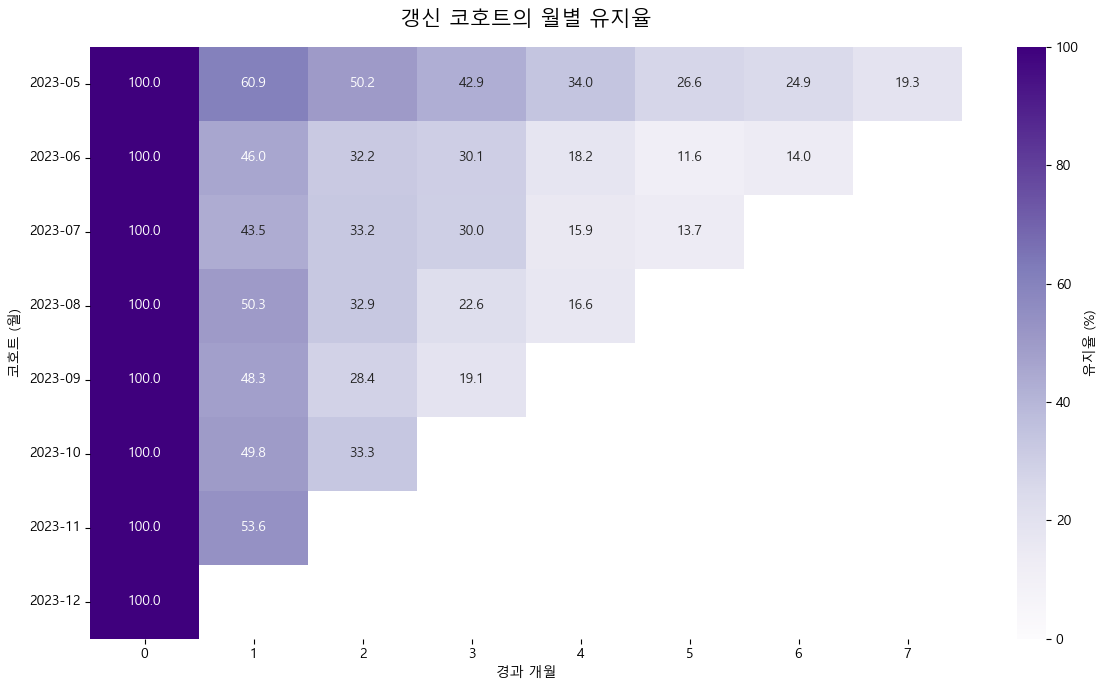

month_index,0,1,2,3,4,5,6,7
cohort_month,,,,,,,,
2023-05,100.0,60.9,50.2,42.9,34.0,26.6,24.9,19.3
2023-06,100.0,46.0,32.2,30.1,18.2,11.6,14.0,NaN
2023-07,100.0,43.5,33.2,30.0,15.9,13.7,NaN,NaN
2023-08,100.0,50.3,32.9,22.6,16.6,NaN,NaN,NaN
2023-09,100.0,48.3,28.4,19.1,NaN,NaN,NaN,NaN
2023-10,100.0,49.8,33.3,NaN,NaN,NaN,NaN,NaN
2023-11,100.0,53.6,NaN,NaN,NaN,NaN,NaN,NaN
2023-12,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
renew_cohort = first_event(renew)[['user_id', 'month']].rename(columns={'month': 'cohort_month'})
ret_renew = renew_retention(renew_cohort)
plot_heatmap(ret_renew, '갱신 코호트의 월별 유지율', cmap='Purples')
ret_renew.round(1)

### 2-3. 재구독 코호트

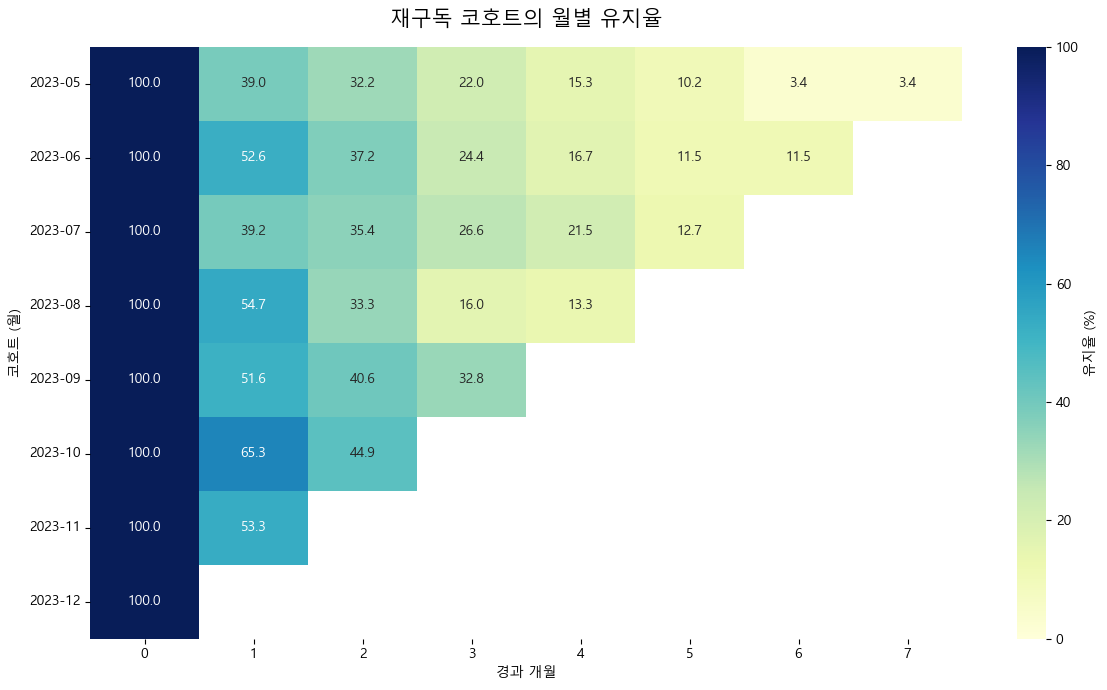

코호트 크기: {Period('2023-05', 'M'): 59, Period('2023-06', 'M'): 78, Period('2023-07', 'M'): 79, Period('2023-08', 'M'): 75, Period('2023-09', 'M'): 64, Period('2023-10', 'M'): 49, Period('2023-11', 'M'): 60, Period('2023-12', 'M'): 99}


month_index,0,1,2,3,4,5,6,7
cohort_month,,,,,,,,
2023-05,100.0,39.0,32.2,22.0,15.3,10.2,3.4,3.4
2023-06,100.0,52.6,37.2,24.4,16.7,11.5,11.5,NaN
2023-07,100.0,39.2,35.4,26.6,21.5,12.7,NaN,NaN
2023-08,100.0,54.7,33.3,16.0,13.3,NaN,NaN,NaN
2023-09,100.0,51.6,40.6,32.8,NaN,NaN,NaN,NaN
2023-10,100.0,65.3,44.9,NaN,NaN,NaN,NaN,NaN
2023-11,100.0,53.3,NaN,NaN,NaN,NaN,NaN,NaN
2023-12,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
resub_cohort = first_event(resub)[['user_id', 'month']].rename(columns={'month': 'cohort_month'})
ret_resub = renew_retention(resub_cohort)
plot_heatmap(ret_resub, '재구독 코호트의 월별 유지율', cmap='YlGnBu')
print('코호트 크기:', resub_cohort.groupby('cohort_month').size().to_dict())
ret_resub.round(1)

> 재구독 코호트는 월 50~80명 수준이라 칸마다 변동이 큽니다.

### 2-4. 1개월 차 유지율 비교

In [12]:
month1 = pd.DataFrame({
    '첫 구독': ret_sub[1],
    '갱신': ret_renew[1],
    '재구독': ret_resub[1],
}).round(1)
print('코호트 평균 1개월 차 유지율 (%)')
print(month1.mean().round(1))
month1

코호트 평균 1개월 차 유지율 (%)
첫 구독    49.8
갱신      50.3
재구독     50.8
dtype: float64


,첫 구독,갱신,재구독
cohort_month,,,
2023-05,54.1,60.9,39.0
2023-06,45.5,46.0,52.6
2023-07,42.6,43.5,39.2
2023-08,49.2,50.3,54.7
2023-09,53.9,48.3,51.6
2023-10,55.2,49.8,65.3
2023-11,48.3,53.6,53.3
2023-12,NaN,NaN,NaN


## 3. 학습 경험과 유지

첫 구독 유저를 기준으로, 구독한 첫 달의 학습량과 첫 콘텐츠 난이도에 따라 이후 유지가 어떻게 다른지 봤습니다.

### 3-1. 첫 달 레슨 완료 수별 갱신 전환율

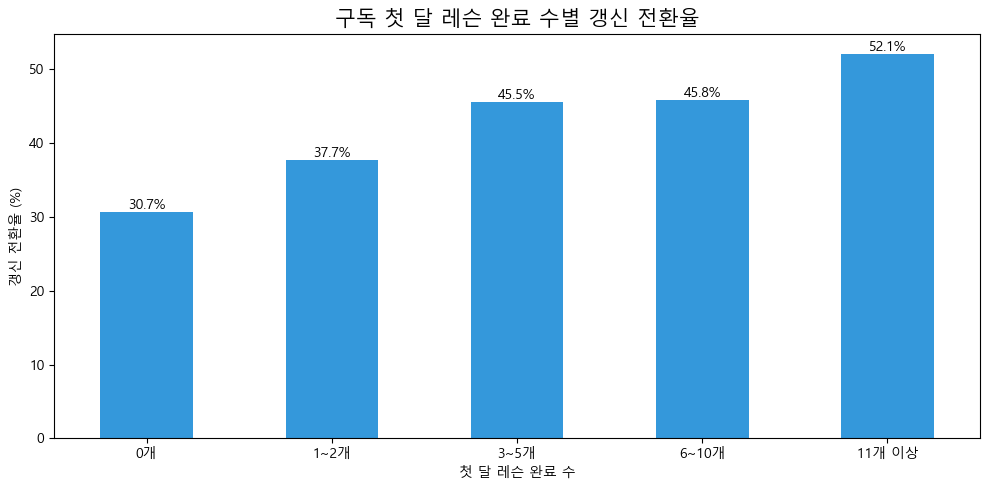

,유저 수,갱신 전환율 (%)
lesson_group,,
0개,969,30.7
1~2개,191,37.7
3~5개,279,45.5
6~10개,406,45.8
11개 이상,3023,52.1


In [13]:
m0 = pd.merge(first_sub[['user_id', 'month']].rename(columns={'month': 'sub_month'}),
              lesson[['user_id', 'month']], on='user_id', how='left')
m0 = m0[m0['month'] == m0['sub_month']]
m0_cnt = m0.groupby('user_id').size().rename('lesson_cnt')

base = first_sub[['user_id', 'month']].rename(columns={'month': 'sub_month'}).set_index('user_id')
base['lesson_cnt'] = m0_cnt
base['lesson_cnt'] = base['lesson_cnt'].fillna(0)
base['lesson_group'] = pd.cut(base['lesson_cnt'], bins=[-1, 0, 2, 5, 10, np.inf],
                              labels=['0개', '1~2개', '3~5개', '6~10개', '11개 이상'])

renew_after = pd.merge(base.reset_index()[['user_id', 'sub_month']], renew[['user_id', 'month']], on='user_id')
renew_after = renew_after[renew_after['month'] > renew_after['sub_month']]
base['is_renewed'] = base.index.isin(renew_after['user_id']).astype(int)

conv = base.groupby('lesson_group', observed=False)['is_renewed'].agg(['count', 'mean'])
conv.columns = ['유저 수', '갱신 전환율 (%)']
conv['갱신 전환율 (%)'] = (conv['갱신 전환율 (%)'] * 100).round(1)

ax = conv['갱신 전환율 (%)'].plot(kind='bar', color='#3498db', figsize=(10, 5))
for i, v in enumerate(conv['갱신 전환율 (%)']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')
plt.title('구독 첫 달 레슨 완료 수별 갱신 전환율', fontsize=15)
plt.xlabel('첫 달 레슨 완료 수')
plt.ylabel('갱신 전환율 (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

conv

> 12월 첫 구독 유저는 관측 기간 안에 갱신 기회가 없어 전환율이 낮게 잡힐 수 있습니다. 같은 기준으로 11월까지만 보려면 `base[base['sub_month'] < '2023-12']`로 다시 계산하면 됩니다.

### 3-2. 첫 달 학습 여부에 따른 월별 이탈률

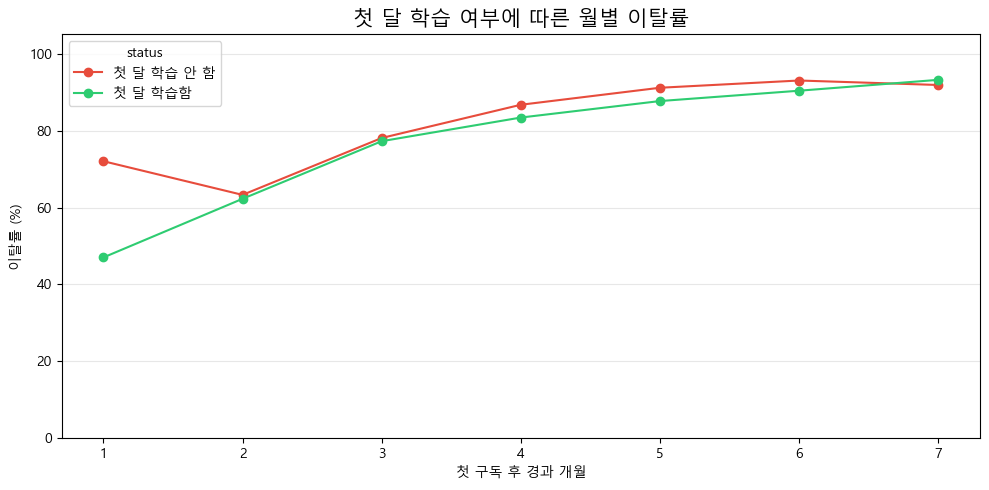

status,첫 달 학습 안 함,첫 달 학습함
month_index,,
1,72.0,47.0
2,63.3,62.3
3,78.1,77.2
4,86.7,83.4
5,91.1,87.7
6,93.0,90.3
7,91.8,93.2


In [14]:
base['status'] = np.where(base['lesson_cnt'] > 0, '첫 달 학습함', '첫 달 학습 안 함')
base['observable'] = month_diff(pd.Series(max_month, index=base.index), base['sub_month'])

ra = renew_after.copy()
ra['month_index'] = month_diff(ra['month'], ra['sub_month'])
ra = ra.merge(base[['status']], left_on='user_id', right_index=True)
active = ra.groupby(['status', 'month_index'])['user_id'].nunique()

rows = []
for (status, k), n in active.items():
    denom = ((base['status'] == status) & (base['observable'] >= k)).sum()
    rows.append({'status': status, 'month_index': k, '이탈률 (%)': 100 - n / denom * 100})
churn = pd.DataFrame(rows).pivot(index='month_index', columns='status', values='이탈률 (%)')

churn.plot(marker='o', figsize=(10, 5), color={'첫 달 학습함': '#2ecc71', '첫 달 학습 안 함': '#e74c3c'})
plt.title('첫 달 학습 여부에 따른 월별 이탈률', fontsize=15)
plt.xlabel('첫 구독 후 경과 개월')
plt.ylabel('이탈률 (%)')
plt.ylim(0, 105)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

churn.round(1)

> 각 경과 개월의 분모는 그 개월 수까지 관측 가능한 유저만 넣었습니다.

### 3-3. 첫 콘텐츠 난이도별 연속 유지율

난이도별 유저 수: {'beginner': 4096, 'intermediate': 270, 'advanced': 252, 'hard': 14}


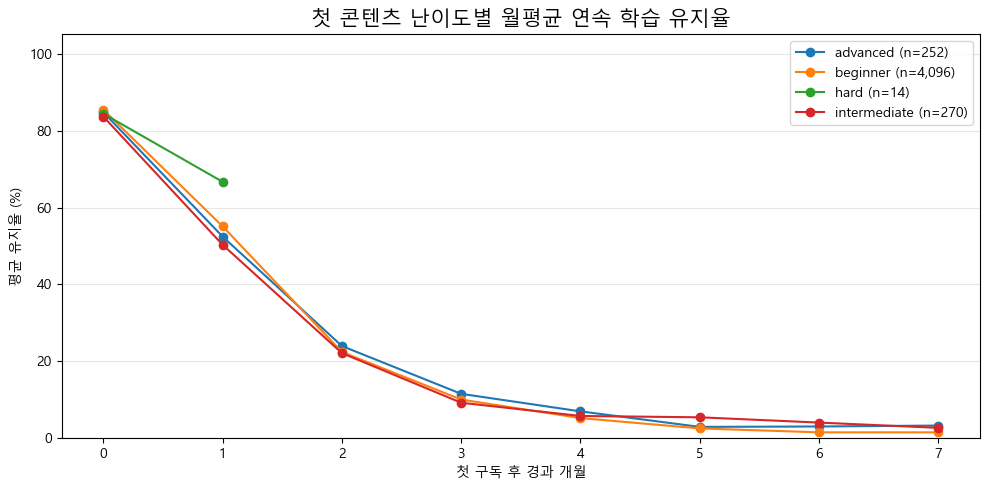

In [15]:
first_diff = first_event(start)[['user_id', 'content.difficulty']]
user_base = pd.merge(first_sub[['user_id', 'month']].rename(columns={'month': 'sub_month'}), first_diff, on='user_id')
print('난이도별 유저 수:', user_base['content.difficulty'].value_counts().to_dict())

act = pd.merge(lesson[['user_id', 'month']], user_base, on='user_id')
act['month_index'] = month_diff(act['month'], act['sub_month'])
act = keep_continuous(act[act['month_index'] >= 0])

plt.figure(figsize=(10, 5))
for lvl, grp in user_base.groupby('content.difficulty'):
    denom = grp.groupby('sub_month')['user_id'].nunique()
    pivot = act[act['content.difficulty'] == lvl].groupby(['sub_month', 'month_index'])['user_id'].nunique().unstack()
    avg = (pivot.divide(denom, axis=0) * 100).mean()
    plt.plot(avg.index, avg.values, marker='o', label=f'{lvl} (n={len(grp):,})')
plt.title('첫 콘텐츠 난이도별 월평균 연속 학습 유지율', fontsize=15)
plt.xlabel('첫 구독 후 경과 개월')
plt.ylabel('평균 유지율 (%)')
plt.ylim(0, 105)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

> 여기서 유지는 해당 달에 레슨 기록이 있는지로 봤습니다(결제 유지가 아닌 학습 유지). 난이도별 표본 차이가 커서 보조 근거로만 사용했습니다.

## 4. 월별 매출 구성

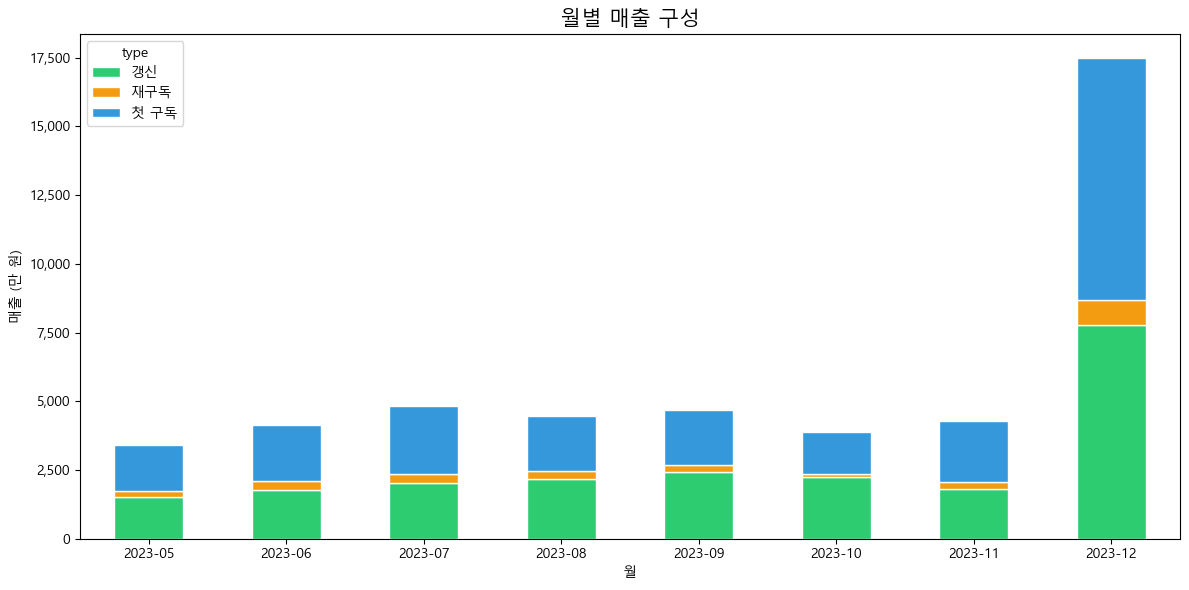

type,갱신,재구독,첫 구독,합계
month,,,,
2023-05,15089737,2327440,16740136,34157313
2023-06,17890130,2976960,20363560,41230650
2023-07,20423659,2992880,24931432,48347971
2023-08,21831885,2906520,20020337,44758742
2023-09,24257401,2499828,20196920,46954149
2023-10,22391321,1205962,15323137,38920420
2023-11,18228844,2279980,22359868,42868692
2023-12,77774312,8867440,88067336,174709088


In [16]:
revenue = pd.concat([
    sub[['month', 'paid_amount']].assign(type='첫 구독'),
    renew[['month', 'paid_amount']].assign(type='갱신'),
    resub[['month', 'paid_amount']].assign(type='재구독'),
])
rev = revenue.pivot_table(index='month', columns='type', values='paid_amount', aggfunc='sum', fill_value=0)
rev = rev[['갱신', '재구독', '첫 구독']]
rev.index = rev.index.astype(str)

ax = (rev / 10000).plot(kind='bar', stacked=True, figsize=(12, 6),
                        color=['#2ecc71', '#f39c12', '#3498db'], edgecolor='white')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x):,}'))
plt.title('월별 매출 구성', fontsize=15)
plt.xlabel('월')
plt.ylabel('매출 (만 원)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

rev['합계'] = rev.sum(axis=1)
rev

> 12월 매출이 다른 달보다 크게 높습니다. 결제 건수만이 아니라 건당 결제액도 함께 확인해야 원인(연간 상품 판매 등)을 판단할 수 있습니다.

In [17]:
dec_check = pd.concat([sub.assign(type='첫 구독'), renew.assign(type='갱신'), resub.assign(type='재구독')])
dec_check.groupby('month').agg(결제건수=('paid_amount', 'size'), 건당평균=('paid_amount', 'mean'),
                              최대=('paid_amount', 'max')).round(0)

,결제건수,건당평균,최대
month,,,
2023-05,1111,30745.0,131600
2023-06,1483,27802.0,131600
2023-07,1797,26905.0,131600
2023-08,1708,26205.0,131600
2023-09,1862,25217.0,131600
2023-10,1612,24144.0,131600
2023-11,1643,26092.0,131600
2023-12,2698,64755.0,131600


## 5. 정리

- 분석 기간(2023.05~12) 동안 월 가입 유저는 4,739명에서 9,474명까지 늘었습니다.
- 갱신 코호트는 1개월 차에 유지율이 44~61%로, 코호트마다 절반 가까이가 첫 달에 이탈했습니다. 2개월 차 이후에도 하락이 이어져 대부분 3개월을 넘기지 못했습니다.
- 갱신 이후보다 구독 직후 첫 달이 가장 큰 이탈 구간이라, 원인을 구독 전후의 학습 경험에서 찾기로 했습니다.
- 첫 달 학습량과 첫 콘텐츠 난이도에 따른 유지율 차이는 3장에서 확인했고, 이 결과는 팀의 Aha Moment 가설 검증으로 이어졌습니다.